# 4 · Validation on synthetic images

Real data have no ground truth: the measured error mixes the algorithm and the setup. Here the scene is known: a camera with the parameters estimated on the real setup, a circle master, a light sheet and a solid with a nominal profile. `lightsheet3d.synthetic` generates the images with the same names and format as the real ones, the pipeline reads them unchanged and the result is compared with the true geometry.

The noise is a Gaussian displacement (in pixels) of the circle centers and of the sheet points before rendering.

In [1]:
import tempfile
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "docs" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from lightsheet3d.solids import CORPO6
from lightsheet3d.synthetic import Scene, evaluate, render_master, render_scan

## Generated images

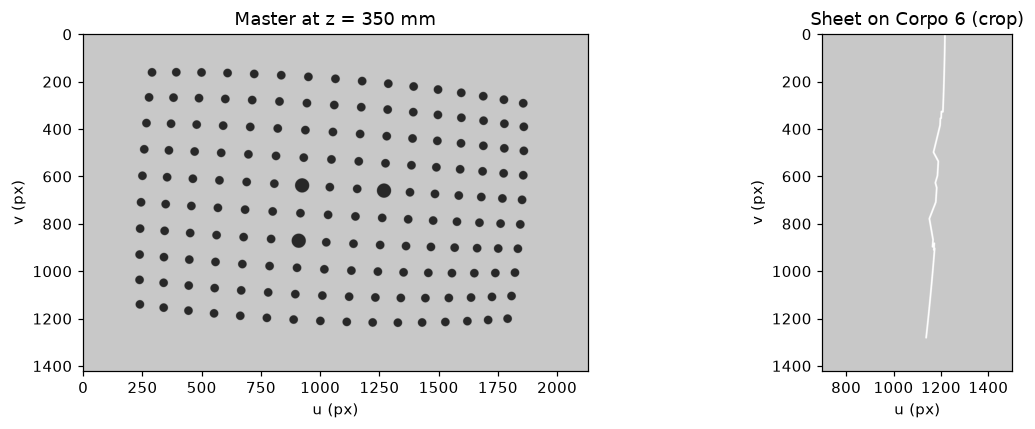

In [2]:
scene = Scene()
master = render_master(scene, 350)
scan = render_scan(scene, CORPO6, shift=-57.0)

fig, axs = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2.4, 1]})
axs[0].imshow(cv.cvtColor(master, cv.COLOR_BGR2RGB)); axs[0].set_title("Master at z = 350 mm")
axs[1].imshow(cv.cvtColor(scan[:, 700:1500], cv.COLOR_BGR2RGB), extent=(700, 1500, scan.shape[0], 0)); axs[1].set_title("Sheet on Corpo 6 (crop)")
for ax in axs:
    ax.grid(False); ax.set(xlabel="u (px)", ylabel="v (px)")
fig.tight_layout(); fig.savefig(FIGURES / "synthetic_images.png", bbox_inches="tight")

## Error versus noise

For each noise level a dataset is generated (master at five heights, sheet on the master, scan), calibrated and measured. The error is the distance of each 3D point from the true nominal profile, in the (y, h) plane.

In [3]:
NOISE = [0.0, 0.25, 0.5, 1.0, 2.0]
SEEDS = range(3)
med, p90 = {}, {}
with tempfile.TemporaryDirectory() as tmp:
    for sigma in NOISE:
        runs = [evaluate(CORPO6, Path(tmp) / f"{sigma}_{seed}", noise_px=sigma, seed=seed) for seed in SEEDS]
        med[sigma] = [np.median(r["dist"]) for r in runs]
        p90[sigma] = [np.percentile(r["dist"], 90) for r in runs]
        print(f"noise {sigma:4.2f} px: median distance {np.mean(med[sigma]):.3f} mm, 90th percentile {np.mean(p90[sigma]):.3f} mm, "
              f"shift error {np.mean([abs(r['shift'] + 57) for r in runs]):.2f} mm")

noise 0.00 px: median distance 0.033 mm, 90th percentile 0.090 mm, shift error 0.03 mm


noise 0.25 px: median distance 0.100 mm, 90th percentile 0.407 mm, shift error 0.02 mm


noise 0.50 px: median distance 0.184 mm, 90th percentile 0.714 mm, shift error 0.04 mm


noise 1.00 px: median distance 0.355 mm, 90th percentile 1.306 mm, shift error 0.06 mm


noise 2.00 px: median distance 0.639 mm, 90th percentile 2.057 mm, shift error 0.16 mm


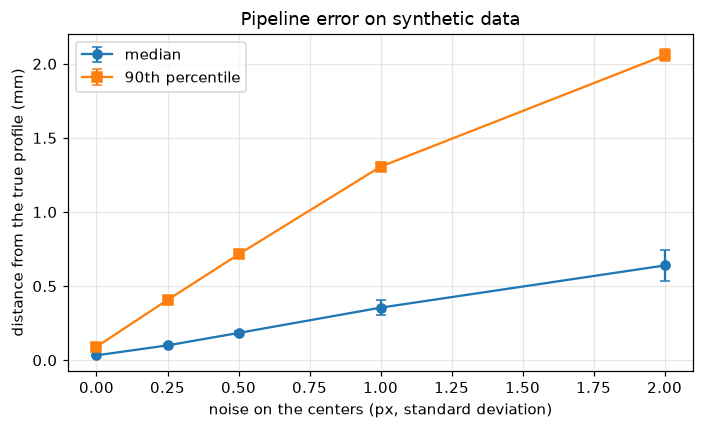

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for series, label, marker in ((med, "median", "o"), (p90, "90th percentile", "s")):
    mean = [np.mean(series[s]) for s in NOISE]
    spread = [np.ptp(series[s]) / 2 for s in NOISE]
    ax.errorbar(NOISE, mean, yerr=spread, marker=marker, capsize=3, label=label)
ax.set(xlabel="noise on the centers (px, standard deviation)", ylabel="distance from the true profile (mm)",
       title="Pipeline error on synthetic data"); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "synthetic_error_vs_noise.png", bbox_inches="tight")

## Sheet extraction: centroid versus Steger

So far the noise displaced the vertices of the sheet. Here we simulate what really differs between the two methods: a blurred sheet (`blur`, standard deviation in pixels) and Gaussian noise on the intensities (`grain`, gray levels). The weighted centroid (`laser_centroids`, the default) uses the saturated core and the edges; `laser_steger` looks for the brightness ridge with Gaussian derivatives and derives the position along the normal. Both look for the sheet where the saturated core is, so they find the same rows.

In [5]:
from lightsheet3d.laser import laser_centroids, laser_steger

CONDITIONS = {"sharp": {}, "blurred\n(1.5 px)": {"blur": 1.5}, "blurred +\ngrain (8)": {"blur": 1.5, "grain": 8}, "very blurred +\ngrain (12)": {"blur": 2.5, "grain": 12}}
EXTRACTORS = {"centroid": laser_centroids, "Steger": laser_steger}
errors = {name: [] for name in EXTRACTORS}
with tempfile.TemporaryDirectory() as tmp:
    for cond, kw in CONDITIONS.items():
        for name, extract in EXTRACTORS.items():
            tag = cond.replace("\n", "_").replace(" ", "")
            runs = [evaluate(CORPO6, Path(tmp) / f"{tag}_{name}_{seed}", seed=seed, extract=extract, **kw) for seed in range(2)]
            errors[name].append(np.mean([np.median(r["dist"]) for r in runs]))
for i, cond in enumerate(CONDITIONS):
    print(f"{cond.replace(chr(10), ' '):28s} centroid {errors['centroid'][i]:.3f} mm | Steger {errors['Steger'][i]:.3f} mm")

sharp                        centroid 0.033 mm | Steger 0.030 mm
blurred (1.5 px)             centroid 0.039 mm | Steger 0.029 mm
blurred + grain (8)          centroid 0.106 mm | Steger 0.060 mm
very blurred + grain (12)    centroid 0.317 mm | Steger 0.166 mm


real, Corpo 6: centroid 0.546 mm | Steger 0.678 mm
real, Corpo 5: centroid 0.622 mm | Steger 0.619 mm


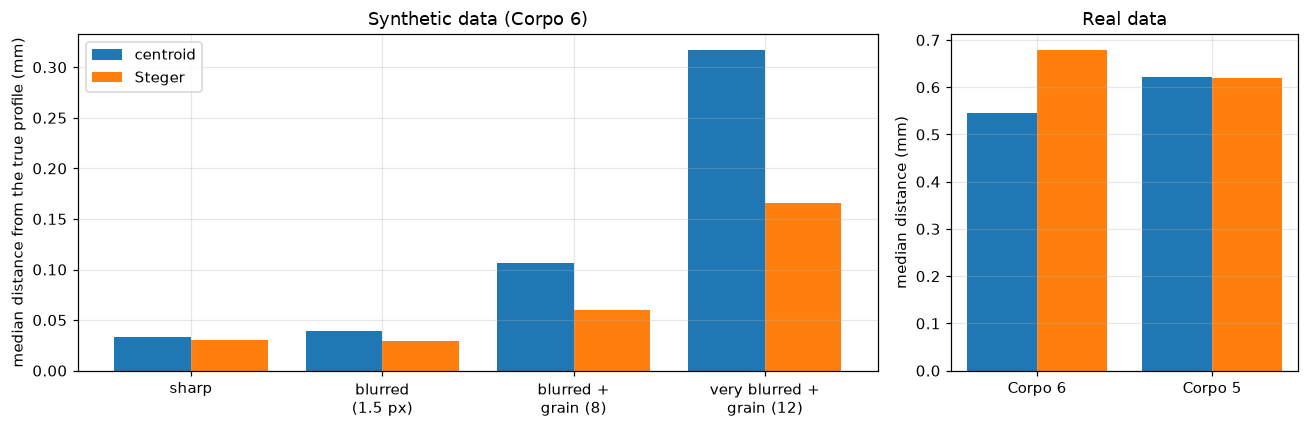

In [6]:
from lightsheet3d.measure import level_to_plate
from lightsheet3d.pipeline import PLATE_Z, calibrate_camera, calibrate_light_plane, scan_points
from lightsheet3d.solids import CORPO5, align, distances, nominal_curve

camera = calibrate_camera(ROOT / "data" / "camera_calibration")
real = {name: [] for name in EXTRACTORS}
for name, extract in EXTRACTORS.items():
    plane = calibrate_light_plane(ROOT / "data" / "light_plane_calibration", camera.model, extract=extract).plane
    for image, solid in (("30o34", CORPO6), ("30o3", CORPO5)):
        X = scan_points(ROOT / "data" / "scans" / f"{image}.jpg", camera.model, plane, extract=extract)
        y, h = X[:, 1], level_to_plate(X[:, 1], PLATE_Z - X[:, 2])
        sign, shift = align(solid, y, h)
        yn, _ = nominal_curve(solid, sign, shift)
        on_solid = (y > yn[1]) & (y < yn[-2])
        real[name].append(float(np.median(distances(solid, sign, shift, y[on_solid], h[on_solid]))))
for i, label in enumerate(("Corpo 6", "Corpo 5")):
    print(f"real, {label}: centroid {real['centroid'][i]:.3f} mm | Steger {real['Steger'][i]:.3f} mm")

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 1.3]})
x = np.arange(len(CONDITIONS))
for k, name in enumerate(EXTRACTORS):
    a.bar(x + 0.4 * (k - 0.5), errors[name], 0.4, label=name)
    b.bar(np.arange(2) + 0.4 * (k - 0.5), real[name], 0.4, label=name)
a.set(xticks=x, xticklabels=list(CONDITIONS), ylabel="median distance from the true profile (mm)", title="Synthetic data (Corpo 6)"); a.legend()
b.set(xticks=range(2), xticklabels=["Corpo 6", "Corpo 5"], ylabel="median distance (mm)", title="Real data"); b.grid(True, alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURES / "stripe_extraction.png", bbox_inches="tight")

## What it shows

* **Without noise** the error is a few hundredths of a millimeter: what remains is pixel quantization and the very steep flanks, which have few points.
* **With noise** the error grows roughly in proportion: at 1 pixel the median is about 0.35 mm.
* **What this notebook fixed** (each item has a test in `tests/`):
  * the calibration invented a linear drift of the master offset along z even when the master did not move (a systematic error of about 0.25 mm without noise): `fit_camera` now removes it;
  * the sharp tips of the peaks were underestimated by about 0.5 mm, because the sheet has a thickness and the per-row centroid cuts them: `measure_peaks` now estimates them from the intersection of the flanks (and from the median of the points on wide planes);
  * the sheet centroid used only the saturated core, with half-pixel resolution: it is now weighted with the intensity on the edges;
  * the OpenCV blob detector discarded the large circles of the "L" when the master was close to the camera.
* **Centroid versus Steger**: with a blurred sheet and noise on the intensities Steger halves the error; on real data, where the sheet is saturated and well contrasted, there is no advantage (Corpo 5 unchanged, Corpo 6 slightly worse). For this reason the centroid remains the default and Steger, 11 times slower, is an option (`--extractor steger`).